In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
data = pd.read_csv("Wholesale customers data.csv")

print("Dataset:")
print(data.head())

print("\nDataset Shape:", data.shape)
print("\nMissing Values:")
print(data.isnull().sum())

Dataset:
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185

Dataset Shape: (440, 8)

Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [3]:
features = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]

X = data[features]

print("\nSelected Features:")
print(X.head())


Selected Features:
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844
3  13265  1196     4221    6404               507        1788
4  22615  5410     7198    3915              1777        5185


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

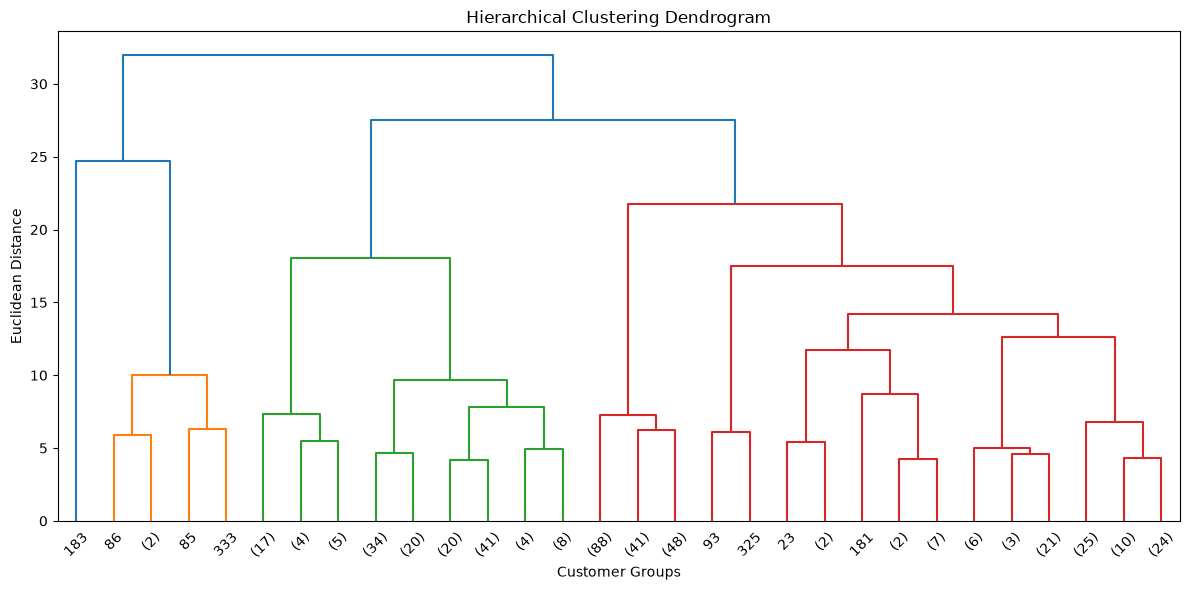

In [5]:
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

In [6]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

data["Cluster"] = model.fit_predict(X_scaled)

print("\nClustered Dataset:")
print(data.head(15))


Clustered Dataset:
    Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
0         2       3  12669   9656     7561     214              2674   
1         2       3   7057   9810     9568    1762              3293   
2         2       3   6353   8808     7684    2405              3516   
3         1       3  13265   1196     4221    6404               507   
4         2       3  22615   5410     7198    3915              1777   
5         2       3   9413   8259     5126     666              1795   
6         2       3  12126   3199     6975     480              3140   
7         2       3   7579   4956     9426    1669              3321   
8         1       3   5963   3648     6192     425              1716   
9         2       3   6006  11093    18881    1159              7425   
10        2       3   3366   5403    12974    4400              5977   
11        2       3  13146   1124     4523    1420               549   
12        2       3  31714  12319    11757  

In [7]:
print("\nNumber of Customers in Each Cluster:")
print(data["Cluster"].value_counts().sort_index())


Number of Customers in Each Cluster:
Cluster
0      6
1    281
2    153
Name: count, dtype: int64


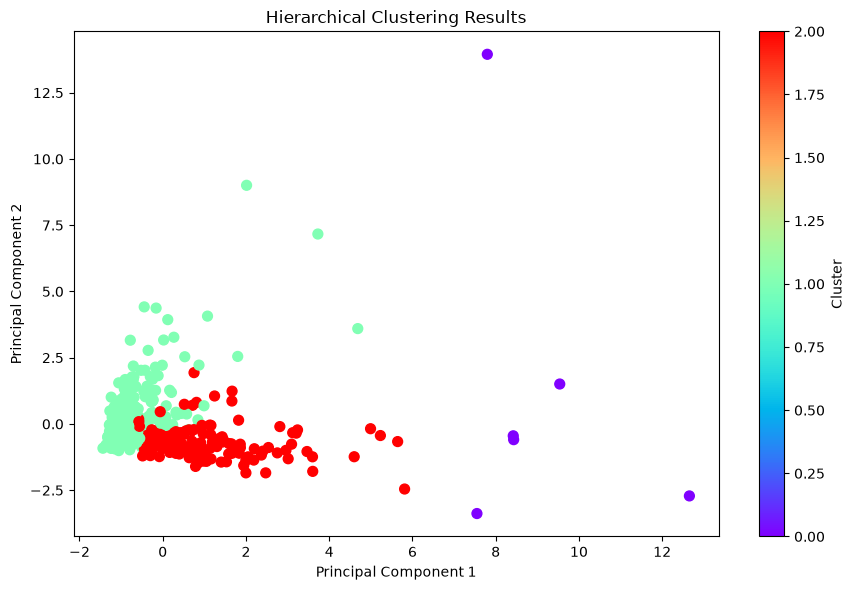

In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=data["Cluster"],
    cmap="rainbow",
    s=50
)

plt.title("Hierarchical Clustering Results")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

In [9]:
print("\nAverage Spending in Each Cluster:")
print(data.groupby("Cluster")[features].mean().round(2))


Average Spending in Each Cluster:
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0        27477.00  43542.17  54588.50  8285.67          25018.33    10247.83
1        15048.93   3017.30   3791.76  3837.32            758.01     1309.90
2         5794.24   9419.89  13761.74  1461.76           5913.38     1577.61
